# Libraries

In [2]:
import pandas as pd
import numpy as np
import os
import tensorflow as tf
import cv2
from keras import backend as K
from keras.layers import Layer, InputSpec
import keras.layers as kl
from glob import glob
from sklearn.metrics import roc_curve, auc
from keras.preprocessing import image
from tensorflow.keras.models import Sequential
from sklearn.metrics import roc_auc_score
from tensorflow.keras import callbacks 
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from  matplotlib import pyplot as plt
from tensorflow.keras import Model
from tensorflow.keras.layers import concatenate, Dense, Conv2D, MaxPooling2D, Flatten, Input, Activation, add, AveragePooling2D, BatchNormalization, Dropout
%matplotlib inline
import shutil
from sklearn.metrics import  precision_score, recall_score, accuracy_score, classification_report, confusion_matrix
from tensorflow.python.platform import build_info as tf_build_info
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.model_selection import train_test_split

from PIL import ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True

from tensorflow.keras.layers import Reshape, Conv2D, BatchNormalization, MaxPooling2D, Flatten, Dense, Input, GlobalAveragePooling2D, GlobalMaxPooling2D
from tensorflow.keras.applications.mobilenet import MobileNet
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint
from tensorflow.keras.preprocessing.image import ImageDataGenerator

2025-04-12 13:55:38.085251: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1744466138.275889      31 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1744466138.327394      31 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
targetnames = ['0_No_DR', '1_Mild_DR', '2_Moderate_DR', '3_Severe_DR', '4_Proliferative_DR']
num_classes = len(targetnames)
batch_size = 16
image_size = 224


In [4]:
train_path = '/kaggle/input/modified-aptos-2019/train/train'
test_path = '/kaggle/input/modified-aptos-2019/test/test'
val_path = '/kaggle/input/modified-aptos-2019/val/val'

# Dataset generation (Train, Test, Validation)

In [5]:
datagen = ImageDataGenerator(preprocessing_function=tf.keras.applications.densenet.preprocess_input)

In [6]:
print("\nTrain Batches: ")
train_batches = datagen.flow_from_directory(directory=train_path,
                                            target_size=(image_size,image_size),
                                            batch_size=batch_size,
                                            shuffle=True)

print("\nTest Batches: ")
test_batches = datagen.flow_from_directory(test_path,
                                          target_size=(image_size,image_size),
                                          batch_size=batch_size,
                                          shuffle=False)
print("\nVal Batches: ")
val_batches = datagen.flow_from_directory(val_path,
                                         target_size=(image_size,image_size),
                                         batch_size=batch_size,
                                         shuffle=False)


Train Batches: 
Found 24909 images belonging to 5 classes.

Test Batches: 
Found 7782 images belonging to 5 classes.

Val Batches: 
Found 6230 images belonging to 5 classes.


### Define Model

In [7]:
from tensorflow.keras.applications.resnet import ResNet50
# Create a new instance of ResNet50
RN50 = ResNet50(weights='imagenet', include_top=False, input_shape=(image_size, image_size, 3), pooling='avg')

I0000 00:00:1744466171.851260      31 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


## Fine tuning

In [8]:
MainInput=Input(shape=(image_size, image_size, 3))

In [9]:
resnet50 = RN50(MainInput)

In [10]:
# Reshape the tensor to have 4 dimensions
from tensorflow.keras.layers import Reshape
reshape = Reshape((8, 8, 32))(resnet50)

In [11]:
conv = Conv2D(filters=256,kernel_size=(7,7), activation="relu",padding="same",kernel_initializer='he_normal')(reshape)
conv = BatchNormalization()(conv)
conv = Conv2D(filters=256,kernel_size=(5,5), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
conv = BatchNormalization()(conv)
conv = Conv2D(filters=256,kernel_size=(3,3), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
conv = BatchNormalization()(conv)
conv = Conv2D(filters=256,kernel_size=(1,1), activation="relu",padding="same",kernel_initializer='he_normal')(conv)
conv = BatchNormalization()(conv)

In [12]:
num_classes = test_batches.num_classes
print(num_classes)

5


In [13]:
conv = (Flatten()(conv))
conv = (Dense(1024,activation="relu")(conv))
conv = Dropout(0.35)(conv)
conv = (Dense(512,activation="relu")(conv))
conv = Dropout(0.25)(conv)
conv = (Dense(num_classes, activation="softmax")(conv))

model_rn50 = Model(inputs=MainInput, outputs=conv)

In [14]:
model_rn50.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)           │ (None, 224, 224, 3)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ resnet50 (Functional)                │ (None, 2048)                │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ reshape (Reshape)                    │ (None, 8, 8, 32)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d (Conv2D)                      │ (None, 8, 8, 256)           │         401,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 8, 8, 256)           │       1,638,656 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 8, 8, 256)           │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 8, 8, 256)           │          65,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 8, 8, 256)           │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 16384)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1024)                │      16,778,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 1024)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 512)                 │         524,800 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 5)                   │           2,565 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 43,593,605 (166.30 MB)

 Trainable params: 43,538,437 (166.09 MB)

 Non-trainable params: 55,168 (215.50 KB)

In [15]:
opt1=tf.keras.optimizers.Adam(learning_rate=0.001,epsilon=0.1)
model_rn50.compile(optimizer=opt1,
             loss='categorical_crossentropy',
             metrics=['accuracy'])

In [16]:
class_weights = {   
                    0: 1.0,   # 0_No_DR
                    1: 1.0,  # 1_Mild_DR
                    2: 1.0,  # 2_Moderate_DR
                    3: 1.0,  # 3_Severe_DR
                    4: 1.0,  # 4_Proliferative_DR
                }

In [17]:
checkpoint = ModelCheckpoint(filepath ='RN50.weights.h5', monitor='val_accuracy', save_best_only=True, save_weights_only=True)
Earlystop = EarlyStopping(monitor='val_accuracy', mode='max', patience=25, min_delta=0.01)

In [18]:
history = model_rn50.fit(train_batches,
                         epochs=25,
                         verbose=2,
                         validation_data=val_batches,
                         callbacks=[checkpoint, Earlystop],
                         class_weight=class_weights) 

Epoch 1/3


/usr/local/lib/python3.11/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:122: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1744466235.344834     112 service.cc:148] XLA service 0x7db3280022e0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1744466235.345534     112 service.cc:156]   StreamExecutor device (0): Tesla P100-PCIE-16GB, Compute Capability 6.0
I0000 00:00:1744466240.339146     112 cuda_dnn.cc:529] Loaded cuDNN version 90300
I0000 00:00:1744466261.788134     112 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1557/1557 - 1653s - 1s/step - accuracy: 0.5926 - loss: 1.0226 - val_accuracy: 0.7361 - val_loss: 0.6738
Epoch 2/3
1557/1557 - 1415s - 909ms/step - accuracy: 0.7547 - loss: 0.6191 - val_accuracy: 0.7417 - val_loss: 0.6626
Epoch 3/3
1557/1557 - 1258s - 808ms/step - accuracy: 0.8440 - loss: 0.4031 - val_accuracy: 0.8748 - val_loss: 0.3318


### Plotting accuracy and loss

Number of epochs trained: 3


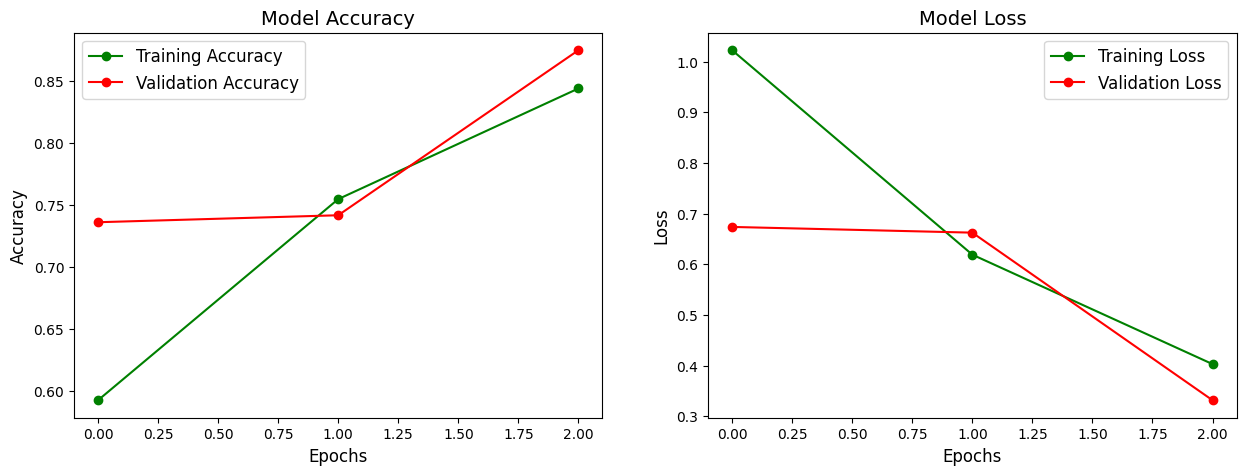

In [19]:
# Determine number of epochs trained
num_epochs_trained = len(history.history['val_loss'])
print(f"Number of epochs trained: {num_epochs_trained}")

## History plotting
epochs = [i for i in range(num_epochs_trained)]
fig , ax = plt.subplots(1,2)
train_acc = history.history['accuracy']
train_loss = history.history['loss']
val_acc = history.history['val_accuracy']
val_loss = history.history['val_loss']
fig.set_size_inches(15,5)

ax[0].plot(epochs , train_acc , 'go-' , label = 'Training Accuracy')
ax[0].plot(epochs , val_acc , 'ro-' , label = 'Validation Accuracy')
title_font = {'fontname':'Times New Roman', 'size':'14', 'color':'black', 'weight':'normal'}
ax[0].set_title('Model Accuracy', fontdict=title_font)
legend_font = {'family': 'Times New Roman', 'size': '12', 'weight': 'normal'}
ax[0].legend(prop=legend_font)
label_font = {'fontname':'Times New Roman', 'size':'12', 'color':'black', 'weight':'normal'}
ax[0].set_xlabel("Epochs",  fontdict=label_font)
ax[0].set_ylabel("Accuracy",  fontdict=label_font)

ax[1].plot(epochs , train_loss , 'g-o' , label = 'Training Loss')
ax[1].plot(epochs , val_loss , 'r-o' , label = 'Validation Loss')
ax[1].set_title('Model Loss', fontdict=title_font)
ax[1].legend(prop=legend_font)
ax[1].set_xlabel("Epochs", fontdict=label_font)
ax[1].set_ylabel("Loss", fontdict=label_font)
plt.show()

In [20]:
from tensorflow.keras import models
model_rn50.load_weights("RN50.weights.h5")

In [21]:
predictions = model_rn50.predict(test_batches)

487/487 ━━━━━━━━━━━━━━━━━━━━ 379s 768ms/step


In [22]:
#geting predictions on test dataset
y_pred = np.argmax(predictions, axis=1)
#getting the true labels per image 
y_true = test_batches.classes
#getting the predicted labels per image 
y_prob = predictions

In [23]:
classnames = ['0_No_DR', '1_Mild_DR', '2_Moderate_DR', '3_Severe_DR', '4_Proliferative_DR']

from tensorflow.keras.utils import to_categorical
y_test = to_categorical(y_true)

report = classification_report(y_true, y_pred, target_names=classnames)

print("\nClassification Report:")
print(report)


Classification Report:
                    precision    recall  f1-score   support

           0_No_DR       0.98      0.95      0.97      1600
         1_Mild_DR       0.87      0.87      0.87      1547
     2_Moderate_DR       0.79      0.77      0.78      1590
       3_Severe_DR       0.86      0.92      0.89      1489
4_Proliferative_DR       0.86      0.87      0.87      1556

          accuracy                           0.88      7782
         macro avg       0.88      0.88      0.88      7782
      weighted avg       0.88      0.88      0.88      7782



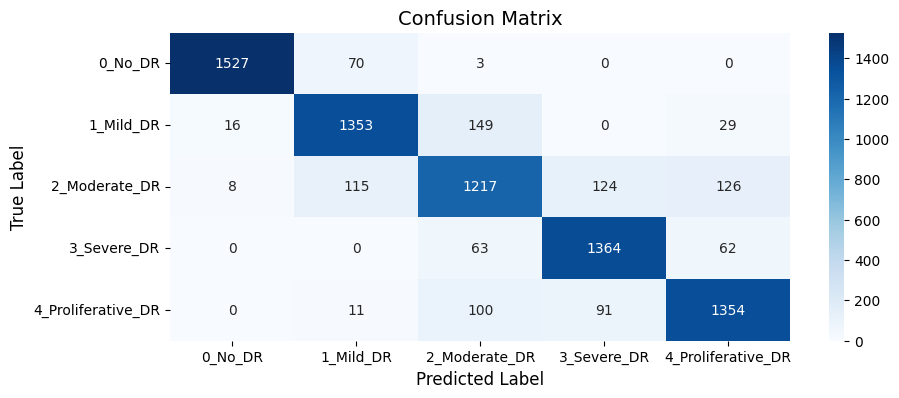

In [24]:
## Confusion Matrix
title_font = {'fontname':'Times New Roman', 'size':'14', 'color':'black', 'weight':'normal'}
label_font = {'fontname':'Times New Roman', 'size':'12', 'color':'black', 'weight':'normal'}

from sklearn.metrics import confusion_matrix
import seaborn as sns
# Creating confusion matrix 
cm = confusion_matrix(y_true, y_pred)
# Plotting the confusion matrix
plt.figure(figsize=(10,4))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues', xticklabels=targetnames, yticklabels=targetnames)
plt.xlabel('Predicted Label', fontdict=label_font)
plt.ylabel('True Label', fontdict=label_font)
plt.title('Confusion Matrix', fontdict=title_font)
plt.show()

## Results

### Individual Class Accuracy 

In [25]:
# y_true are the true labels of the test set
# y_pred are the predicted labels of the test set
accuracy = accuracy_score(y_true, y_pred)
# Calculate accuracy for each class
class_accuracy = cm.diagonal()/cm.sum(axis=1)
print("Overall accuracy: {:.2f}%".format(accuracy*100))
print("Accuracy for each class:")
for i, acc in enumerate(class_accuracy):
    print("Class {}: {:.2f}%".format(i, acc*100))

Overall accuracy: 87.57%
Accuracy for each class:
Class 0: 95.44%
Class 1: 87.46%
Class 2: 76.54%
Class 3: 91.61%
Class 4: 87.02%


### Individual Class Weighted Precision

In [26]:
report = classification_report(y_true, y_pred, output_dict=True)
# Extract weighted precision for each class
class_precision = {}
for class_label in report.keys():
    if class_label == 'weighted avg':
        class_precision['weighted'] = report[class_label]['precision']
    elif class_label.isdigit():
        class_precision[int(class_label)] = report[class_label]['precision']
print("Weighted precision for each class:")
for i, precision in class_precision.items():
    if i == 'weighted':
        print("Weighted precision: {:.2f}%".format(precision*100))
    else:
        print("Class {}: {:.2f}%".format(i, precision*100))

Weighted precision for each class:
Class 0: 98.45%
Class 1: 87.35%
Class 2: 79.44%
Class 3: 86.38%
Class 4: 86.19%
Weighted precision: 87.60%


### Individual Class Weighted Recall

In [27]:
report = classification_report(y_true, y_pred, output_dict=True)
# Extract weighted recall for each class
class_recall = {}
for class_label in report.keys():
    if class_label == 'weighted avg':
        class_recall['weighted'] = report[class_label]['recall']
    elif class_label.isdigit():
        class_recall[int(class_label)] = report[class_label]['recall']
print("Weighted recall for each class:")
for i, recall in class_recall.items():
    if i == 'weighted':
        print("Weighted Recall: {:.2f}%".format(recall*100))
    else:
        print("Class {}: {:.2f}%".format(i, recall*100))

Weighted recall for each class:
Class 0: 95.44%
Class 1: 87.46%
Class 2: 76.54%
Class 3: 91.61%
Class 4: 87.02%
Weighted Recall: 87.57%


### Individual Class Weighted F1-score

In [28]:
report = classification_report(y_true, y_pred, output_dict=True)
# Extract weighted F1-score for each class
class_f1 = {}
for class_label in report.keys():
    if class_label == 'weighted avg':
        class_f1['weighted'] = report[class_label]['f1-score']
    elif class_label.isdigit():
        class_f1[int(class_label)] = report[class_label]['f1-score']
print("Weighted F1-score for each class:")
for i, f1_score in class_f1.items():
    if i == 'weighted':
        print("Weighted F1-score: {:.2f}%".format(f1_score*100))
    else:
        print("Class {}: {:.2f}%".format(i, f1_score*100))

Weighted F1-score for each class:
Class 0: 96.92%
Class 1: 87.40%
Class 2: 77.96%
Class 3: 88.92%
Class 4: 86.60%
Weighted F1-score: 87.56%


### Individual Class Precision, Recall and F1-score

In [29]:
from sklearn.metrics import precision_recall_fscore_support

precision_class, recall_class, f1_class, support_class = precision_recall_fscore_support(y_true, y_pred, average=None)
print('Class-wise weighted precision, recall, and F1-score:')
for i in range(len(precision_class)):
    print('Class {}: Precision={:.2f}, Recall={:.2f}, F1-score={:.2f}'.format(i, precision_class[i], recall_class[i], f1_class[i]))


Class-wise weighted precision, recall, and F1-score:
Class 0: Precision=0.98, Recall=0.95, F1-score=0.97
Class 1: Precision=0.87, Recall=0.87, F1-score=0.87
Class 2: Precision=0.79, Recall=0.77, F1-score=0.78
Class 3: Precision=0.86, Recall=0.92, F1-score=0.89
Class 4: Precision=0.86, Recall=0.87, F1-score=0.87


### Individual Class Weighted Sensitivity

In [30]:
from sklearn.metrics import recall_score

# Weighted Sensitivity = Weighted Recall
sensitivity = recall_score(y_true, y_pred, average='weighted')
print("Weighted Sensitivity: ", sensitivity)

# Class-wise Sensitivity = Recall per class
class_wise_sensitivity = recall_score(y_true, y_pred, average=None)

# Print sensitivity for each class
for i, score in enumerate(class_wise_sensitivity):
    print(f"Class {i}: sensitivity = {score}")


Weighted Sensitivity:  0.8757388846054999
Class 0: sensitivity = 0.954375
Class 1: sensitivity = 0.8745959922430511
Class 2: sensitivity = 0.7654088050314466
Class 3: sensitivity = 0.916051040967092
Class 4: sensitivity = 0.8701799485861182


### Individual Class Weighted Specificity

In [32]:
from sklearn.metrics import confusion_matrix
import numpy as np

# Confusion matrix: rows = actual, cols = predicted
cm = confusion_matrix(y_true, y_pred)
num_classes = cm.shape[0]

specificities = []
for i in range(num_classes):
    TN = np.sum(np.delete(np.delete(cm, i, axis=0), i, axis=1))
    FP = np.sum(np.delete(cm, i, axis=0)[:, i])
    specificity = TN / (TN + FP) if (TN + FP) > 0 else 0
    specificities.append(specificity)
    print(f"Class {i}: specificity = {specificity}")

# Weighted specificity
class_counts = np.bincount(y_true)
weighted_specificity = np.average(specificities, weights=class_counts)
print("Weighted Specificity:", weighted_specificity)


Class 0: specificity = 0.9961177612423164
Class 1: specificity = 0.9685645549318364
Class 2: specificity = 0.9491279069767442
Class 3: specificity = 0.965835054822819
Class 4: specificity = 0.9651461612592355
Weighted Specificity: 0.9690525546274515


### Accuracy

In [33]:
print("Accuracy: " + str(accuracy_score(y_true, y_pred)))
import numpy as np
from sklearn.metrics import accuracy_score

Accuracy: 0.8757388846054999


In [34]:
# Calculate top-1 accuracy
top1_acc = accuracy_score(y_true, y_pred)
print("Top-1 Accuracy:", top1_acc)

# Calculate top-2 accuracy
y_pred_top2 = np.argsort(-predictions, axis=1)[:, :2] # Get the top 2 predicted classes
top2_acc = np.mean(np.array([y_true[i] in y_pred_top2[i] for i in range(len(y_true))]))
print("Top-2 Accuracy:", top2_acc)

# Calculate top-3 accuracy
y_pred_top3 = np.argsort(-predictions, axis=1)[:, :3] # Get the top 3 predicted classes
top3_acc = np.mean(np.array([y_true[i] in y_pred_top3[i] for i in range(len(y_true))]))
print("Top-3 Accuracy:", top3_acc)
from sklearn.metrics import f1_score

Top-1 Accuracy: 0.8757388846054999
Top-2 Accuracy: 0.9775122076586996
Top-3 Accuracy: 0.9982009766126959


### Weighted Evaluation Measures

### Macro Evaluation Measures

### Micro Evaluation Measures

In [36]:
print("Micro Precision: "+ str(precision_score(y_true, y_pred, average='micro')))
print("Micro Recall: "+ str(recall_score(y_true, y_pred, average='micro')))
print("Micro F1-Score: "+ str(f1_score(y_true, y_pred, average='micro')))
print("Micro Sensitivity: "+ str(recall_score(y_true, y_pred, average='micro')))
print("Micro Specificity: "+ str(recall_score(y_true, y_pred, average='micro')))

Micro Precision: 0.8757388846054999
Micro Recall: 0.8757388846054999
Micro F1-Score: 0.8757388846054999
Micro Sensitivity: 0.8757388846054999
Micro Specificity: 0.8757388846054999


## ROC

### Compute ROC curve and ROC area for each class

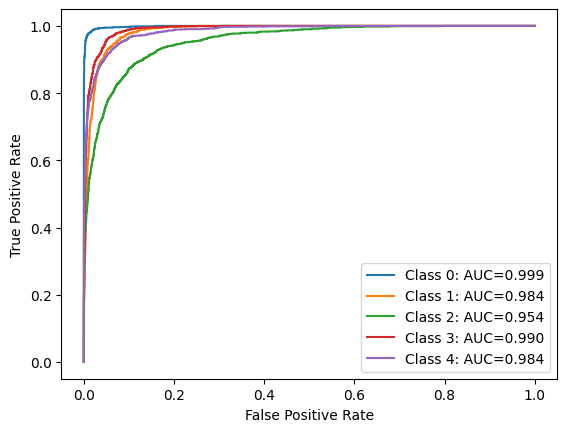

In [37]:
fpr = {}
tpr = {}
roc_auc = dict()
for i in range(num_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test[:, i], y_prob[:, i], drop_intermediate=False)
    roc_auc[i] = auc(fpr[i], tpr[i])


# plot the ROC curve for each class
for i in range(num_classes):
    plt.plot(fpr[i], tpr[i], label='Class {}: AUC={:.3f}'.format(i, roc_auc[i]))

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

## MCC and Kappa Score

In [38]:
from sklearn.metrics import matthews_corrcoef, cohen_kappa_score

# y_true are the true labels of the test set
# y_pred are the predicted labels of the test set
mcc = matthews_corrcoef(y_true, y_pred)
kappa = cohen_kappa_score(y_true, y_pred)
print("MCC: {:.2f}%".format(mcc*100))
print("Kappa Score: {:.2f}%".format(kappa*100))

MCC: 84.48%
Kappa Score: 84.47%


In [39]:
### Individual Class Wise MCC and Kappa

from sklearn.metrics import confusion_matrix, matthews_corrcoef, cohen_kappa_score
# y_true are the true labels of the test set
# y_pred are the predicted labels of the test set
conf_mat = confusion_matrix(y_true, y_pred)
mcc_per_class = {}
kappa_per_class = {}

for i in range(len(conf_mat)):
    tp = conf_mat[i][i]
    fp = sum(conf_mat[:, i]) - tp
    fn = sum(conf_mat[i, :]) - tp
    tn = sum(sum(conf_mat)) - tp - fp - fn

    mcc_per_class[i] = matthews_corrcoef([1 if x==i else 0 for x in y_true], [1 if x==i else 0 for x in y_pred])
    kappa_per_class[i] = cohen_kappa_score([1 if x==i else 0 for x in y_true], [1 if x==i else 0 for x in y_pred])

print("MCC per class:")
for i, mcc in mcc_per_class.items():
    print("Class {}: {:.2f}%".format(i, mcc*100))

print("Kappa Score per class:")
for i, kappa in kappa_per_class.items():
    print("Class {}: {:.2f}%".format(i, kappa*100))

MCC per class:
Class 0: 96.16%
Class 1: 84.28%
Class 2: 72.46%
Class 3: 86.26%
Class 4: 83.23%
Kappa Score per class:
Class 0: 96.14%
Class 1: 84.28%
Class 2: 72.44%
Class 3: 86.20%
Class 4: 83.23%
